# Tarea 3

Eric Alarcon Dolynko - 202220287

## Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display

np.set_printoptions(precision=8, suppress=True)

## Validaciones

In [4]:
def validar_matriz(A, b, x0):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float).reshape(-1)
    x0 = np.asarray(x0, dtype=float).reshape(-1)

    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A debe ser una matriz cuadrada.")

    if not np.all(np.isfinite(A)):
        raise ValueError("A contiene valores no finitos.")

    if not np.all(np.isfinite(b)) or not np.all(np.isfinite(x0)):
        raise ValueError("Los vectores contienen valores no finitos.")

    if b.size != A.shape[0] or x0.size != A.shape[0]:
        raise ValueError("Las dimensiones de A, b y x0 no coinciden.")

    if not np.allclose(A, A.T, rtol=1e-10, atol=1e-12):
        raise ValueError("A no es simétrica.")

    try:
        np.linalg.cholesky(A)
    except np.linalg.LinAlgError:
        raise ValueError("A no es definida positiva.")

    return A, b, x0

# Revisar Valores propios

In [5]:
def analizar_matriz(A):
    valores_propios = np.linalg.eigvalsh(A)

    lambda_min = valores_propios[0]
    lambda_max = valores_propios[-1]

    alpha_optimo = 2 / (lambda_min + lambda_max)
    alpha_limite = 2 / lambda_max

    return {
        "valores_propios": valores_propios,
        "lambda_min": lambda_min,
        "lambda_max": lambda_max,
        "alpha_optimo": alpha_optimo,
        "alpha_limite": alpha_limite,
        "numero_condicion": lambda_max / lambda_min
    }


def radio_espectral(A, alpha):
    valores_propios = np.linalg.eigvalsh(A)
    return np.max(np.abs(1 - alpha * valores_propios))

## Método Iterativo

In [6]:
def metodo_iterativo(A, b, x0, alpha, tolerancia=1e-8, max_iteraciones=1000):
    solucion_exacta = np.linalg.solve(A, b)
    solucion_actual = x0.copy()

    historial = [solucion_actual.copy()]
    errores = [np.linalg.norm(solucion_actual - solucion_exacta)]
    residuos = [np.linalg.norm(b - A @ solucion_actual)]

    escala_residuo = max(1.0, np.linalg.norm(b))
    convergio = residuos[-1] / escala_residuo < tolerancia

    for _ in range(max_iteraciones):
        if convergio:
            break

        solucion_actual = solucion_actual + alpha * (b - A @ solucion_actual)

        historial.append(solucion_actual.copy())
        errores.append(np.linalg.norm(solucion_actual - solucion_exacta))
        residuos.append(np.linalg.norm(b - A @ solucion_actual))

        convergio = residuos[-1] / escala_residuo < tolerancia

        if not np.all(np.isfinite(solucion_actual)):
            convergio = False
            break

    return {
        "solucion": solucion_actual,
        "solucion_exacta": solucion_exacta,
        "historial": np.array(historial),
        "errores": np.array(errores),
        "residuos": np.array(residuos),
        "iteraciones": len(historial) - 1,
        "convergio": convergio,
        "alpha": alpha,
        "radio_espectral": radio_espectral(A, alpha)
    }

# Parámetros

In [7]:
A = [
    [5, 1, 0, 0, 0],
    [1, 5, 1, 0, 0],
    [0, 1, 5, 1, 0],
    [0, 0, 1, 5, 1],
    [0, 0, 0, 1, 5]
]

b = [1, 1, 1, 1, 1]

x0 = [0, 0, 0, 0, 0]

usar_alpha_optimo = True
alpha_personalizado = 0.25

tolerancia = 1e-8
max_iteraciones = 1000

# Ejecución

In [8]:
# iteraciones , error , ambas
criterio_parada = "ambas"

valores_alpha = [
    0.5,
    0.75,
    1.0,
    1.25,
    1.5
]

A, b, x0 = validar_matriz(A, b, x0)
analisis = analizar_matriz(A)

alpha_optimo = analisis["alpha_optimo"]
alpha_limite = analisis["alpha_limite"]

alpha = (
    alpha_optimo
    if usar_alpha_optimo
    else alpha_personalizado
)

def ejecutar_iteraciones(A, b, x0, alpha, tolerancia, max_iteraciones, criterio):
    solucion_exacta = np.linalg.solve(A, b)
    solucion_actual = x0.copy()

    historial = [solucion_actual.copy()]
    errores = [np.linalg.norm(solucion_actual - solucion_exacta)]
    residuos = [np.linalg.norm(b - A @ solucion_actual)]

    escala_residuo = max(1.0, np.linalg.norm(b))

    for _ in range(max_iteraciones):
        error_alcanzado = residuos[-1] / escala_residuo < tolerancia

        if criterio in ("error", "ambas") and error_alcanzado:
            break

        solucion_actual = solucion_actual + alpha * (b - A @ solucion_actual)

        historial.append(solucion_actual.copy())
        errores.append(np.linalg.norm(solucion_actual - solucion_exacta))
        residuos.append(np.linalg.norm(b - A @ solucion_actual))

        if not np.all(np.isfinite(solucion_actual)):
            break

    convergio = (
        np.isfinite(residuos[-1])
        and residuos[-1] / escala_residuo < tolerancia
    )

    return {
        "alpha": alpha,
        "solucion": solucion_actual,
        "solucion_exacta": solucion_exacta,
        "historial": np.array(historial),
        "errores": np.array(errores),
        "residuos": np.array(residuos),
        "iteraciones": len(historial) - 1,
        "convergio": convergio,
        "radio_espectral": radio_espectral(A, alpha)
    }


resultado = ejecutar_iteraciones(
    A, b, x0, alpha,
    tolerancia, max_iteraciones, criterio_parada
)

comparaciones = {}

for factor in valores_alpha:
    alpha_comparacion = factor * alpha_optimo

    comparaciones[f"{factor:.2f} α₀"] = ejecutar_iteraciones(
        A, b, x0,
        alpha_comparacion,
        tolerancia,
        max_iteraciones,
        criterio_parada
    )

print("Valores propios:", analisis["valores_propios"])
print("Alpha óptimo:", alpha_optimo)
print("Intervalo de convergencia:", (0, alpha_limite))
print("Alpha utilizado:", alpha)
print("Criterio de parada:", criterio_parada)
print("Radio espectral:", resultado["radio_espectral"])
print("Convergencia teórica:", 0 < alpha < alpha_limite)
print("Tolerancia alcanzada:", resultado["convergio"])
print("Iteraciones realizadas:", resultado["iteraciones"])
print("Solución aproximada:", resultado["solucion"])
print("Solución exacta:", resultado["solucion_exacta"])
print("Error final:", resultado["errores"][-1])
print("Residuo final:", resultado["residuos"][-1])

Valores propios: [3.26794919 4.         5.         6.         6.73205081]
Alpha óptimo: 0.2
Intervalo de convergencia: (0, np.float64(0.2970862902210112))
Alpha utilizado: 0.2
Criterio de parada: ambas
Radio espectral: 0.34641016151377535
Convergencia teórica: True
Tolerancia alcanzada: True
Iteraciones realizadas: 18
Solución aproximada: [0.17272727 0.13636364 0.14545454 0.13636364 0.17272727]
Solución exacta: [0.17272727 0.13636364 0.14545455 0.13636364 0.17272727]
Error final: 1.6694356937604865e-09
Residuo final: 1.1146399569429202e-08


# Gráficas

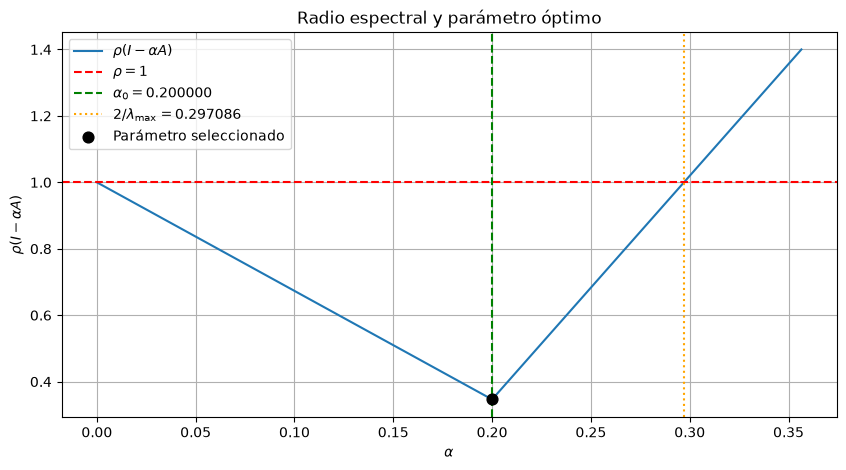

In [9]:
alphas = np.linspace(0, 1.2 * alpha_limite, 600)
radios = np.array([radio_espectral(A, valor) for valor in alphas])

plt.figure(figsize=(10, 5))

plt.plot(alphas, radios, label=r"$\rho(I-\alpha A)$")
plt.axhline(1, color="red", linestyle="--", label=r"$\rho=1$")
plt.axvline(alpha_optimo, color="green", linestyle="--", label=rf"$\alpha_0={alpha_optimo:.6f}$")
plt.axvline(alpha_limite, color="orange", linestyle=":", label=rf"$2/\lambda_{{\max}}={alpha_limite:.6f}$")

plt.scatter(
    alpha,
    radio_espectral(A, alpha),
    color="black",
    s=60,
    zorder=5,
    label="Parámetro seleccionado"
)

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\rho(I-\alpha A)$")
plt.title("Radio espectral y parámetro óptimo")
plt.legend()
plt.grid(True)
plt.show()

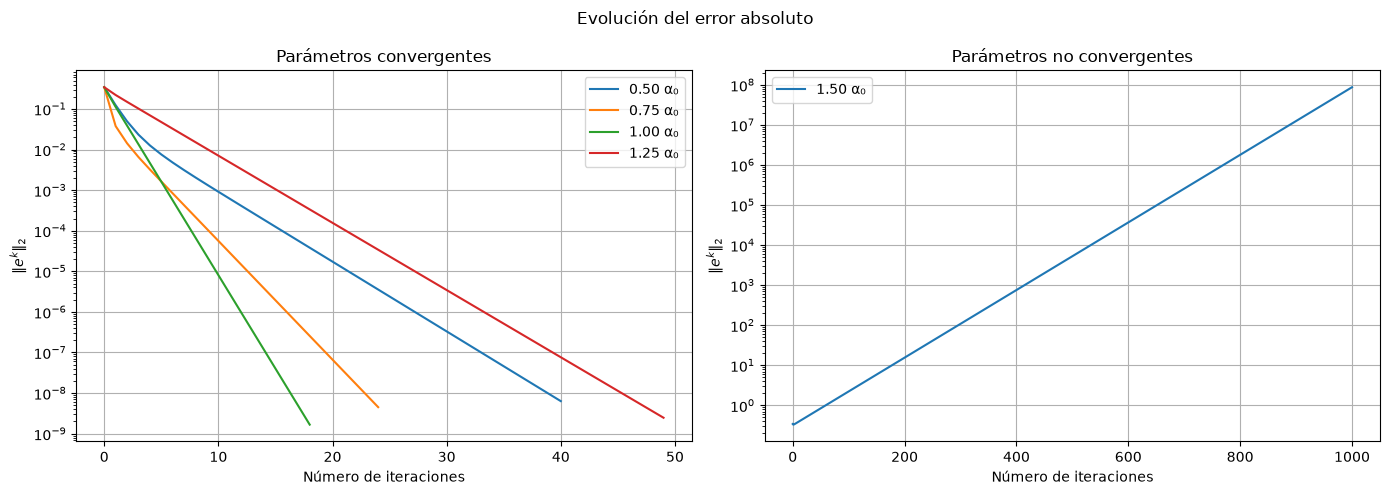

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

for nombre, experimento in comparaciones.items():
    errores = np.maximum(experimento["errores"], 1e-16)
    iteraciones = np.arange(len(errores))

    if experimento["radio_espectral"] < 1:
        ejes[0].semilogy(iteraciones, errores, label=nombre)
    else:
        ejes[1].semilogy(iteraciones, errores, label=nombre)

ejes[0].set_title("Parámetros convergentes")
ejes[1].set_title("Parámetros no convergentes")

for eje in ejes:
    eje.set_xlabel("Número de iteraciones")
    eje.set_ylabel(r"$\|e^k\|_2$")
    eje.legend()
    eje.grid(True)

plt.suptitle("Evolución del error absoluto")
plt.tight_layout()
plt.show()

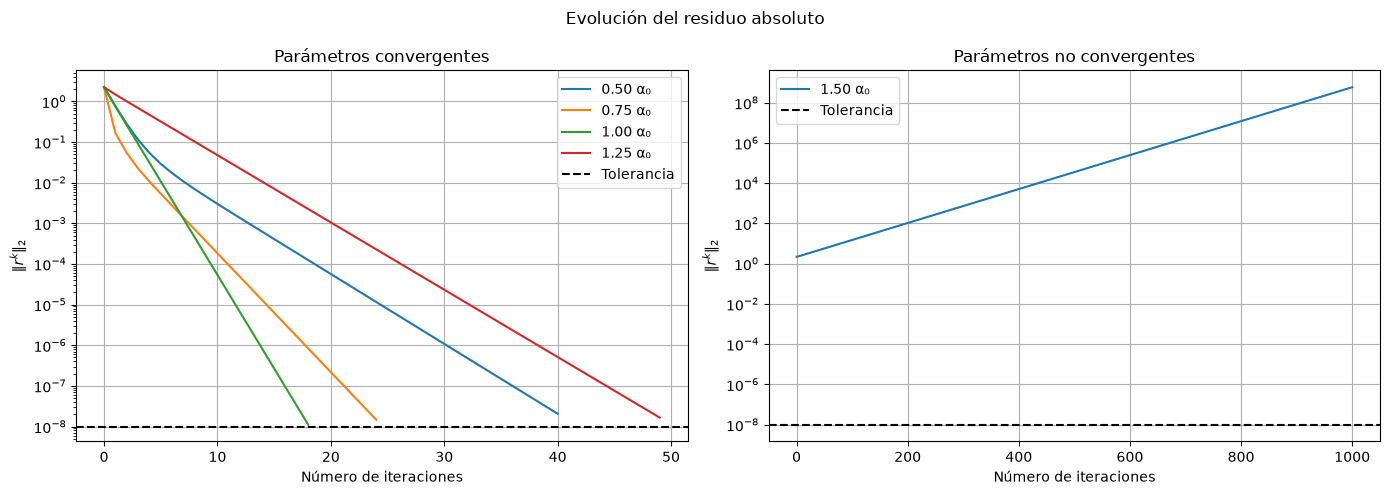

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

for nombre, experimento in comparaciones.items():
    residuos = np.maximum(experimento["residuos"], 1e-16)
    iteraciones = np.arange(len(residuos))

    if experimento["radio_espectral"] < 1:
        ejes[0].semilogy(iteraciones, residuos, label=nombre)
    else:
        ejes[1].semilogy(iteraciones, residuos, label=nombre)

ejes[0].set_title("Parámetros convergentes")
ejes[1].set_title("Parámetros no convergentes")

for eje in ejes:
    eje.axhline(tolerancia, color="black", linestyle="--", label="Tolerancia")
    eje.set_xlabel("Número de iteraciones")
    eje.set_ylabel(r"$\|r^k\|_2$")
    eje.legend()
    eje.grid(True)

plt.suptitle("Evolución del residuo absoluto")
plt.tight_layout()
plt.show()

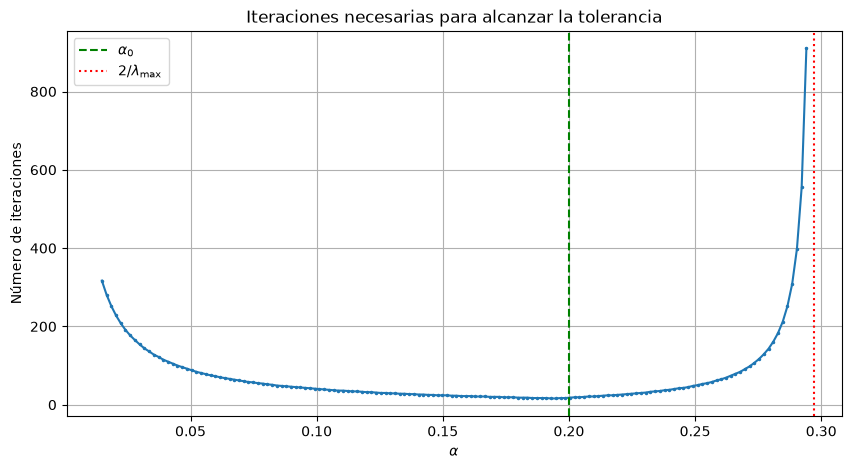

In [12]:
alphas_prueba = np.linspace(
    0.05 * alpha_limite,
    0.99 * alpha_limite,
    150
)

iteraciones_necesarias = []

for alpha_prueba in alphas_prueba:
    experimento = ejecutar_iteraciones(
        A,
        b,
        x0,
        alpha_prueba,
        tolerancia,
        max_iteraciones,
        "error"
    )

    iteraciones_necesarias.append(
        experimento["iteraciones"]
        if experimento["convergio"]
        else np.nan
    )

plt.figure(figsize=(10, 5))

plt.plot(alphas_prueba, iteraciones_necesarias, marker=".", markersize=3)
plt.axvline(alpha_optimo, color="green", linestyle="--", label=r"$\alpha_0$")
plt.axvline(alpha_limite, color="red", linestyle=":", label=r"$2/\lambda_{\max}$")

plt.xlabel(r"$\alpha$")
plt.ylabel("Número de iteraciones")
plt.title("Iteraciones necesarias para alcanzar la tolerancia")
plt.legend()
plt.grid(True)
plt.show()

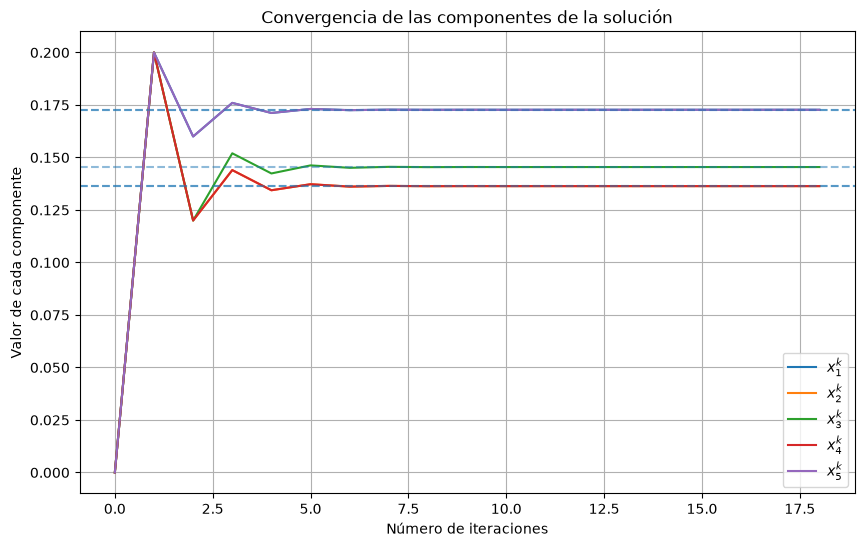

In [13]:
historial = resultado["historial"]
solucion_exacta = resultado["solucion_exacta"]
iteraciones = np.arange(len(historial))

plt.figure(figsize=(10, 6))

for componente in range(A.shape[0]):
    plt.plot(
        iteraciones,
        historial[:, componente],
        label=rf"$x_{{{componente + 1}}}^k$"
    )

    plt.axhline(
        solucion_exacta[componente],
        linestyle="--",
        alpha=0.5
    )

plt.xlabel("Número de iteraciones")
plt.ylabel("Valor de cada componente")
plt.title("Convergencia de las componentes de la solución")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
solucion_aproximada = resultado["solucion"]
solucion_exacta = resultado["solucion_exacta"]

error = np.linalg.norm(solucion_aproximada - solucion_exacta)
residuo = np.linalg.norm(b - A @ solucion_aproximada)

print("RESULTADOS DEL MÉTODO ITERATIVO")
print("=" * 45)

print(f"Respuesta aproximada: {solucion_aproximada}")
print(f"Respuesta exacta:     {solucion_exacta}")

print(f"\nError ||xᵏ - x||₂:    {error:.10e}")
print(f"Residuo ||b - Axᵏ||₂: {residuo:.10e}")

print(f"\nAlpha utilizado:      {alpha:.10f}")
print(f"Alpha óptimo:         {alpha_optimo:.10f}")
print(f"Radio espectral:      {resultado['radio_espectral']:.10f}")

print(f"\nIteraciones:          {resultado['iteraciones']}")
print(f"Tolerancia:           {tolerancia:.2e}")
print(f"Convergencia teórica: {resultado['radio_espectral'] < 1}")
print(f"Tolerancia alcanzada: {residuo < tolerancia}")

tabla_resultados = pd.DataFrame({
    "Componente": np.arange(1, A.shape[0] + 1),
    "Respuesta aproximada": solucion_aproximada,
    "Respuesta exacta": solucion_exacta,
    "Error absoluto": np.abs(solucion_aproximada - solucion_exacta)
})

display(tabla_resultados)

RESULTADOS DEL MÉTODO ITERATIVO
Respuesta aproximada: [0.17272727 0.13636364 0.14545454 0.13636364 0.17272727]
Respuesta exacta:     [0.17272727 0.13636364 0.14545455 0.13636364 0.17272727]

Error ||xᵏ - x||₂:    1.6694356938e-09
Residuo ||b - Axᵏ||₂: 1.1146399569e-08

Alpha utilizado:      0.2000000000
Alpha óptimo:         0.2000000000
Radio espectral:      0.3464101615

Iteraciones:          18
Tolerancia:           1.00e-08
Convergencia teórica: True
Tolerancia alcanzada: False


,Componente,Respuesta aproximada,Respuesta exacta,Error absoluto
0,1,0.172727,0.172727,5.472494e-10
1,2,0.136364,0.136364,7.036064e-10
2,3,0.145455,0.145455,1.094499e-09
3,4,0.136364,0.136364,7.036064e-10
4,5,0.172727,0.172727,5.472494e-10
